# Pronóstico de demanda por sede

**Pregunta:** ¿cuántos tickets va a vender cada sede la próxima semana?

Saberlo ayuda a decidir cuánto personal programar y cuánto insumo comprar. Hoy esa decisión suele tomarse "a ojo" con lo que se vendió la semana pasada. En este notebook comparo ese método contra un modelo de machine learning.

> Los datos son **ficticios** (`generar_datos.py`): dos años de ventas diarias de 4 sedes, con estacionalidad, feriados peruanos y promociones.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("data/ventas_diarias.csv", parse_dates=["fecha"])
df.head()

,fecha,sede,tickets,venta_soles,promo,feriado
0,2024-10-01,Sede Centro,145,5092.05,0,0
1,2024-10-02,Sede Centro,161,6046.53,0,0
2,2024-10-03,Sede Centro,169,6353.24,0,0
3,2024-10-04,Sede Centro,221,8570.90,0,0
4,2024-10-05,Sede Centro,242,9255.19,0,0


## 1. Exploración

In [2]:
print(df.shape)
print(df["fecha"].min().date(), "->", df["fecha"].max().date())
df.groupby("sede")[["tickets", "venta_soles"]].agg(["mean", "sum"]).round(0)

(2920, 6)
2024-10-01 -> 2026-09-30


tickets         venta_soles           
               mean     sum        mean        sum
sede                                              
Sede Centro   207.0  151368      7871.0  5745730.0
Sede Norte    161.0  117775      5567.0  4063570.0
Sede Playa    109.0   79708      4586.0  3347851.0
Sede Sur      138.0  100592      4971.0  3628620.0

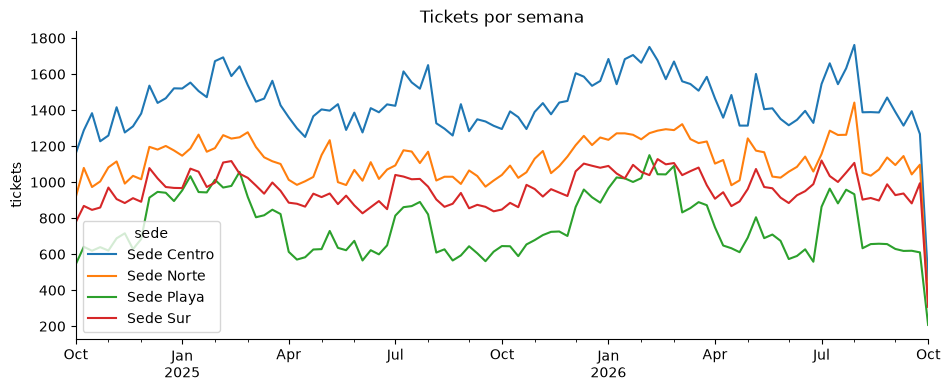

In [3]:
semanal = df.groupby(["sede", pd.Grouper(key="fecha", freq="W")])["tickets"].sum().unstack(0)
semanal.plot(title="Tickets por semana")
plt.ylabel("tickets"); plt.xlabel("")
plt.show()

Se ven dos cosas: los picos de **verano** (enero–marzo) y de **julio**, y que la **Sede Playa** cambia mucho más que las demás según la temporada.

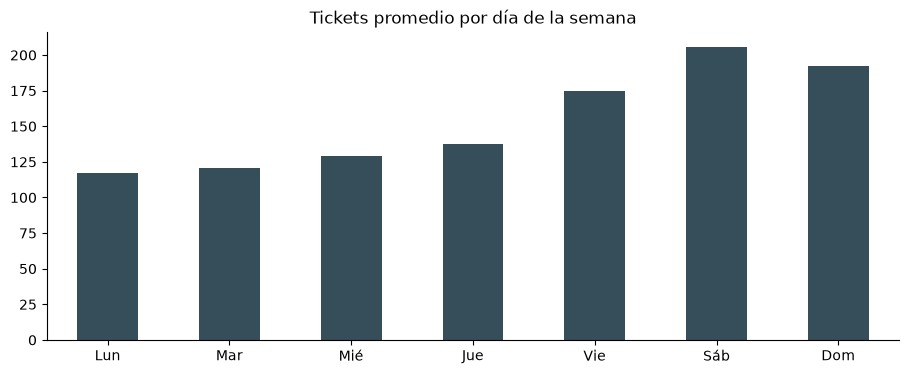

In [4]:
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
por_dia = df.assign(dia=df["fecha"].dt.day_of_week).groupby("dia")["tickets"].mean()
por_dia.index = dias
por_dia.plot(kind="bar", title="Tickets promedio por día de la semana", color="#364D5A")
plt.xticks(rotation=0); plt.show()

In [5]:
efecto = df.groupby(["feriado", "promo"])["tickets"].mean().unstack()
efecto.index = ["Día normal", "Feriado"]; efecto.columns = ["Sin promo", "Con promo"]
efecto.round(0)

,Sin promo,Con promo
Día normal,151.0,183.0
Feriado,177.0,220.0


El viernes, el sábado y el domingo venden bastante más que el lunes. Los feriados y las promociones también suben la demanda. Todas son señales que el modelo puede aprovechar.

## 2. Variables para el modelo

In [6]:
def crear_variables(datos: pd.DataFrame) -> pd.DataFrame:
    d = datos.sort_values(["sede", "fecha"]).copy()
    d["dia_semana"] = d["fecha"].dt.day_of_week
    d["mes"] = d["fecha"].dt.month
    d["dia_mes"] = d["fecha"].dt.day
    g = d.groupby("sede")["tickets"]
    # Solo uso información disponible con 7 días de anticipación
    d["lag_7"] = g.shift(7)
    d["lag_14"] = g.shift(14)
    d["media_4_semanas"] = g.transform(lambda s: (s.shift(7) + s.shift(14) + s.shift(21) + s.shift(28)) / 4)
    d["media_movil_7"] = g.transform(lambda s: s.shift(7).rolling(7).mean())
    d = pd.get_dummies(d, columns=["sede"], prefix="", prefix_sep="", dtype=int).assign(sede=d["sede"])
    return d.dropna()

datos = crear_variables(df)
variables = ["dia_semana", "mes", "dia_mes", "promo", "feriado", "lag_7", "lag_14",
             "media_4_semanas", "media_movil_7", "Sede Centro", "Sede Norte", "Sede Playa", "Sede Sur"]
datos[["fecha", "sede", "tickets"] + variables].tail()

,fecha,sede,tickets,dia_semana,mes,dia_mes,promo,feriado,lag_7,lag_14,media_4_semanas,media_movil_7,Sede Centro,Sede Norte,Sede Playa,Sede Sur
2185,2026-09-26,Sede Sur,199,5,9,26,0,0,162.0,174.0,176.00,129.857143,0,0,0,1
2186,2026-09-27,Sede Sur,223,6,9,27,1,0,150.0,177.0,169.75,126.000000,0,0,0,1
2187,2026-09-28,Sede Sur,101,0,9,28,0,0,102.0,91.0,96.50,127.571429,0,0,0,1
2188,2026-09-29,Sede Sur,106,1,9,29,0,0,97.0,88.0,96.25,128.857143,0,0,0,1
2189,2026-09-30,Sede Sur,100,2,9,30,0,0,101.0,111.0,111.00,127.428571,0,0,0,1


**Separación por tiempo, no al azar:** entreno con todo hasta julio de 2026 y pruebo con las últimas 8 semanas. Así simulo pronosticar fechas que el modelo nunca vio, como pasaría en la vida real.

In [7]:
corte = df["fecha"].max() - pd.Timedelta(weeks=8)
train, test = datos[datos["fecha"] <= corte], datos[datos["fecha"] > corte]
print(f"Entrenamiento: {len(train)} filas | Prueba: {len(test)} filas (desde {corte.date()})")

Entrenamiento: 2584 filas | Prueba: 224 filas (desde 2026-08-05)


## 3. Modelos

In [8]:
modelo = GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=4, random_state=0)
modelo.fit(train[variables], train["tickets"])

resultados = test[["fecha", "sede", "tickets"]].copy()
resultados["Semana pasada"] = test["lag_7"]
resultados["Promedio 4 semanas"] = test["media_4_semanas"]
resultados["Gradient Boosting"] = modelo.predict(test[variables])

def metricas(col):
    return pd.Series({
        "MAE (tickets)": mean_absolute_error(resultados["tickets"], resultados[col]),
        "MAPE": mean_absolute_percentage_error(resultados["tickets"], resultados[col]),
    })

tabla = pd.DataFrame({c: metricas(c) for c in ["Semana pasada", "Promedio 4 semanas", "Gradient Boosting"]}).T
tabla["MAPE"] = (tabla["MAPE"] * 100).round(1).astype(str) + " %"
tabla["MAE (tickets)"] = tabla["MAE (tickets)"].round(1)
tabla

,MAE (tickets),MAPE
Semana pasada,15.7,10.9 %
Promedio 4 semanas,17.1,13.0 %
Gradient Boosting,10.7,7.6 %


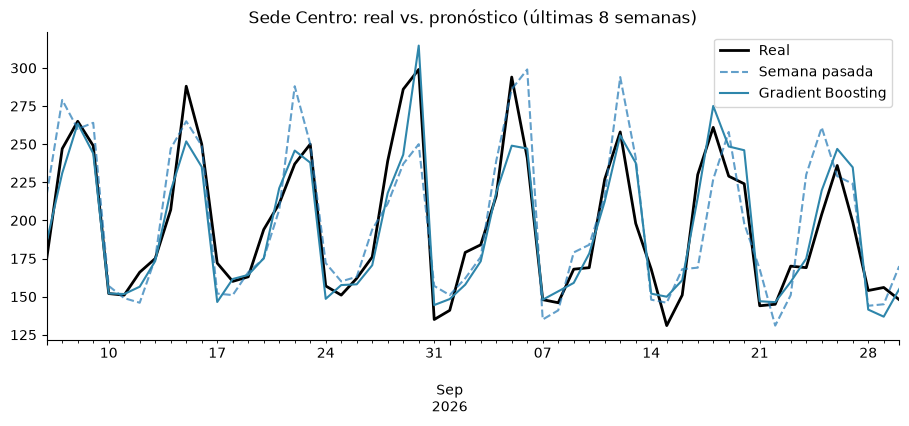

In [9]:
sede = "Sede Centro"
r = resultados[resultados["sede"] == sede].set_index("fecha")
ax = r["tickets"].plot(label="Real", color="black", linewidth=2)
r["Semana pasada"].plot(ax=ax, label="Semana pasada", linestyle="--", alpha=0.7)
r["Gradient Boosting"].plot(ax=ax, label="Gradient Boosting", color="#2E86AB")
ax.set_title(f"{sede}: real vs. pronóstico (últimas 8 semanas)"); ax.set_xlabel(""); ax.legend()
plt.show()

In [10]:
error_sede = resultados.groupby("sede").apply(
    lambda g: pd.Series({
        "MAPE semana pasada": mean_absolute_percentage_error(g["tickets"], g["Semana pasada"]) * 100,
        "MAPE modelo": mean_absolute_percentage_error(g["tickets"], g["Gradient Boosting"]) * 100,
    }), include_groups=False).round(1)
error_sede

,MAPE semana pasada,MAPE modelo
sede,,
Sede Centro,10.7,6.3
Sede Norte,11.4,8.6
Sede Playa,12.3,8.3
Sede Sur,9.1,7.1


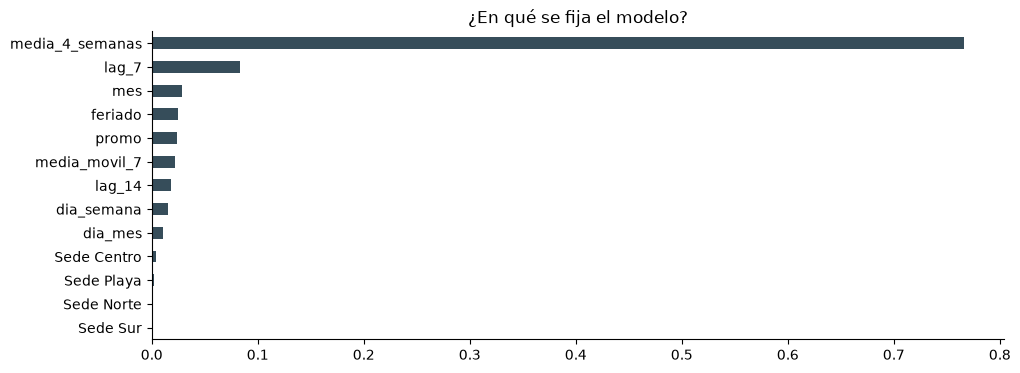

In [11]:
importancia = pd.Series(modelo.feature_importances_, index=variables).sort_values()
importancia.plot(kind="barh", title="¿En qué se fija el modelo?", color="#364D5A")
plt.show()

## 4. Conclusiones

In [12]:
mejora = 1 - mean_absolute_error(resultados["tickets"], resultados["Gradient Boosting"]) / \
             mean_absolute_error(resultados["tickets"], resultados["Semana pasada"])
print(f"El modelo reduce el error frente a 'usar la semana pasada' en {mejora:.0%}.")

El modelo reduce el error frente a 'usar la semana pasada' en 32%.


- Usar lo que se vendió la semana pasada falla mucho en feriados, en días de promoción y en los cambios de temporada.
- El modelo aprende el patrón semanal, el efecto de feriados y promociones y el comportamiento distinto de cada sede, y **reduce el error de forma clara**.
- Para la operación, esto se traduce en programar mejor al personal y comprar insumos con menos merma.

**Siguientes pasos**
- Probar con datos reales del POS (agregados por día y sede).
- Agregar variables externas: clima, eventos y quincenas.
- Pronosticar por producto o familia, no solo tickets totales.
- Publicar el pronóstico semanal en un dashboard de Power BI.